In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("muki2003/yolo-drone-detection-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/muki2003/yolo-drone-detection-dataset


In [3]:
!pip install ultralytics;

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 17.1 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 kB 5.1 MB/s eta 0:00:00


In [4]:
import os 
from pathlib import Path 
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
import torch
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [17]:
from pathlib import Path

def create_yolo_yaml():
    base_path = "/kaggle/input/datasets/muki2003/yolo-drone-detection-dataset"

    yaml_content = f"""# YOLO Dataset Configuration
path: {base_path}

train: train/images
val: valid/images

nc: 1

names:
  0: drone
"""

    yaml_path = Path("/kaggle/working/data.yaml")

    with open(yaml_path, "w", encoding="utf-8") as f:
        f.write(yaml_content)

    print(f"Done: {yaml_path}")
    print("\nYAML Content:\n")
    print(yaml_content)


create_yolo_yaml()

Done: /kaggle/working/data.yaml

YAML Content:

# YOLO Dataset Configuration
path: /kaggle/input/datasets/muki2003/yolo-drone-detection-dataset

train: train/images
val: valid/images

nc: 1

names:
  0: drone



In [8]:
!find /kaggle/input/datasets/muki2003/yolo-drone-detection-dataset -maxdepth 3 -type d

/kaggle/input/datasets/muki2003/yolo-drone-detection-dataset
/kaggle/input/datasets/muki2003/yolo-drone-detection-dataset/drone_dataset
/kaggle/input/datasets/muki2003/yolo-drone-detection-dataset/drone_dataset/valid
/kaggle/input/datasets/muki2003/yolo-drone-detection-dataset/drone_dataset/valid/labels
/kaggle/input/datasets/muki2003/yolo-drone-detection-dataset/drone_dataset/valid/images
/kaggle/input/datasets/muki2003/yolo-drone-detection-dataset/drone_dataset/train
/kaggle/input/datasets/muki2003/yolo-drone-detection-dataset/drone_dataset/train/labels
/kaggle/input/datasets/muki2003/yolo-drone-detection-dataset/drone_dataset/train/images


Images found: 1012


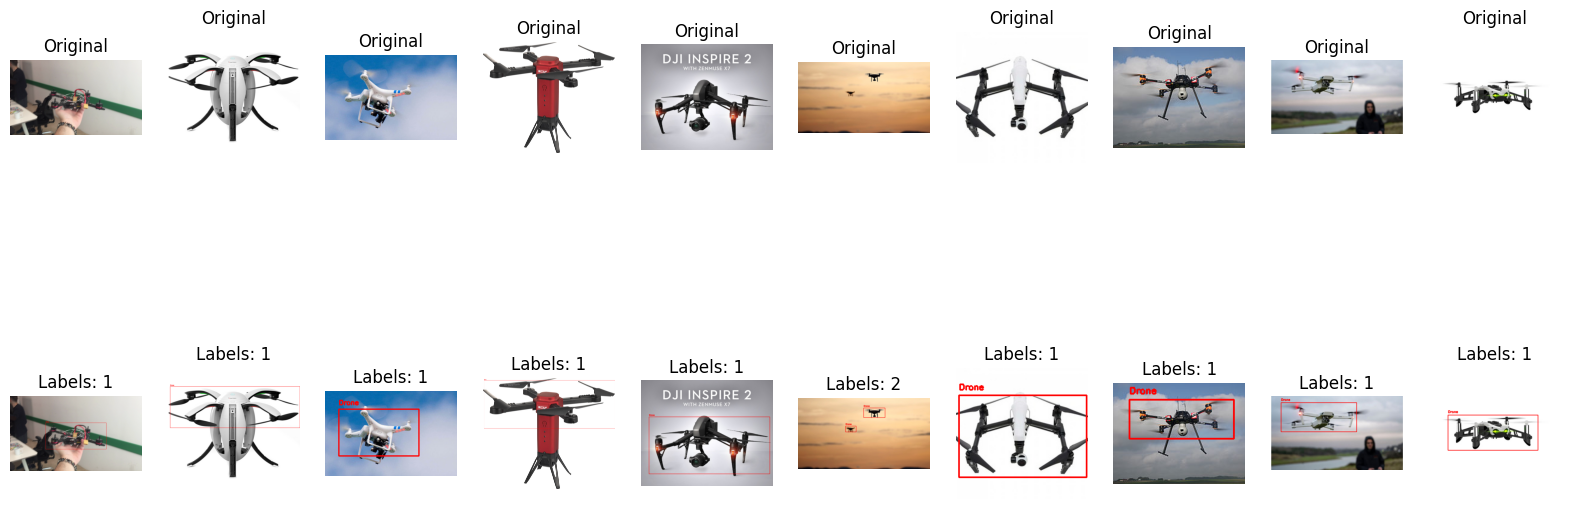

In [18]:
from pathlib import Path
import random
import cv2
import matplotlib.pyplot as plt

def show_data_samples(num_samples=6):

    base_path = Path(
        "/kaggle/input/datasets/muki2003/yolo-drone-detection-dataset/drone_dataset"
    )

    train_images_path = base_path / "train" / "images"
    train_labels_path = base_path / "train" / "labels"

    image_files = (
        list(train_images_path.glob("*.jpg")) +
        list(train_images_path.glob("*.png")) +
        list(train_images_path.glob("*.jpeg"))
    )

    print("Images found:", len(image_files))

    samples = random.sample(
        image_files,
        min(num_samples, len(image_files))
    )

    fig, axes = plt.subplots(
        2,
        len(samples),
        figsize=(20,8)
    )

    for i, image_path in enumerate(samples):

        image = cv2.imread(str(image_path))
        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        label_path = train_labels_path / f"{image_path.stem}.txt"

        image_box = image.copy()

        h, w = image.shape[:2]
        count = 0

        if label_path.exists():

            with open(label_path) as f:
                lines = f.readlines()

            count = len(lines)

            for line in lines:

                cls, xc, yc, bw, bh = map(
                    float,
                    line.split()
                )

                xc *= w
                yc *= h
                bw *= w
                bh *= h

                x1 = int(xc - bw/2)
                y1 = int(yc - bh/2)
                x2 = int(xc + bw/2)
                y2 = int(yc + bh/2)

                cv2.rectangle(
                    image_box,
                    (x1,y1),
                    (x2,y2),
                    (255,0,0),
                    2
                )

                cv2.putText(
                    image_box,
                    "Drone",
                    (x1,y1-10),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (255,0,0),
                    2
                )


        axes[0,i].imshow(image)
        axes[0,i].axis("off")
        axes[0,i].set_title("Original")

        axes[1,i].imshow(image_box)
        axes[1,i].axis("off")
        axes[1,i].set_title(f"Labels: {count}")

    plt.show()


show_data_samples(10)

In [19]:
model = YOLO("yolo12n.pt")

In [20]:
import torch
print("cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("device name:", torch.cuda.get_device_name(0))
    print("current device:", torch.cuda.current_device())

cuda available: True
device name: Tesla T4
current device: 0


In [21]:
from pathlib import Path

yaml_path = Path("/kaggle/working/data.yaml")

yaml_content = """
path: /kaggle/input/datasets/muki2003/yolo-drone-detection-dataset/drone_dataset

train: train/images
val: valid/images

nc: 1

names:
  0: drone
"""

yaml_path.write_text(yaml_content)

print("Fixed YAML:")
print(yaml_path.read_text())

Fixed YAML:

path: /kaggle/input/datasets/muki2003/yolo-drone-detection-dataset/drone_dataset

train: train/images
val: valid/images

nc: 1

names:
  0: drone



In [22]:
results = model.train(
    data="/kaggle/working/data.yaml",
    epochs=20,
    imgsz=416,
    batch=16,
    device=0
)

Ultralytics 8.4.152 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=Fa

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/20      1.58G      1.526       1.51      1.466          6        416: 100% ━━━━━━━━━━━━ 64/64 6.0it/s 10.7s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 3.7it/s 2.9s0.2s
                   all        347        369      0.515      0.442      0.409       0.14

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/20      1.58G      1.564      1.515      1.507          6        416: 100% ━━━━━━━━━━━━ 64/64 6.1it/s 10.4s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 3.6it/s 3.1s0.2s
                   all        347        369      0.486      0.454      0.407       0.17

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/20      1.58G      1.561       1.46      1.503         13        416: 100% ━━━━━━━━━━━━ 64/64 6.0it/s 10.7s0.3s
                 Class     Images  Inst

In [23]:
from ultralytics import YOLO

model = YOLO("/kaggle/working/runs/detect/train-2/weights/best.pt")

metrics = model.val(
    data="/kaggle/working/data.yaml",
    imgsz=416,
    batch=16,
    device=0
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.152 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv12n summary (fused): 159 layers, 2,556,923 parameters, 0 gradients, 7.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 227.5±282.7 MB/s, size: 170.5 KB)
val: Scanning /kaggle/input/datasets/muki2003/yolo-drone-detection-dataset/drone_dataset/valid/labels... 347 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 347/347 702.2it/s 0.5s0.2s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/muki2003/yolo-drone-detection-dataset/drone_dataset/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 5.3it/s 4.1s0.1s
                   all        347        369      0.923      0.791      0.885      0.544
Speed: 0.4ms preprocess, 3.6ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
mAP50: 0.8852253100788541
mAP50-95: 0.5440269609445901
Precisi

In [ ]:
/kaggle/input/datasets/sadrazh79/smandef7/CAR.jpg

In [24]:
from ultralytics import YOLO

model = YOLO("/kaggle/working/runs/detect/train-2/weights/best.pt")

results = model.predict(
    source="/kaggle/input/datasets/sadrazh79/smandef7/CAR.jpg",
    imgsz=416,
    conf=0.5,
    save=True,
    device=0
)

print(results[0].boxes)


image 1/1 /kaggle/input/datasets/sadrazh79/smandef7/CAR.jpg: 320x416 (no detections), 14.0ms
Speed: 1.7ms preprocess, 14.0ms inference, 0.7ms postprocess per image at shape (1, 3, 320, 416)
Results saved to /kaggle/working/runs/detect/predict
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([], device='cuda:0')
conf: tensor([], device='cuda:0')
data: tensor([], device='cuda:0', size=(0, 6))
id: None
is_track: False
orig_shape: (3000, 4000)
shape: torch.Size([0, 6])
xywh: tensor([], device='cuda:0', size=(0, 4))
xywhn: tensor([], device='cuda:0', size=(0, 4))
xyxy: tensor([], device='cuda:0', size=(0, 4))
xyxyn: tensor([], device='cuda:0', size=(0, 4))


In [25]:
from ultralytics import YOLO

model = YOLO("/kaggle/working/runs/detect/train-2/weights/best.pt")

model.export(
    format="onnx",
    imgsz=416,
    simplify=True,
    opset=12
)

Ultralytics 8.4.152 🚀 Python-3.12.13 torch-2.10.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLOv12n summary (fused): 159 layers, 2,556,923 parameters, 0 gradients, 2.8 GFLOPs

PyTorch: starting from '/kaggle/working/runs/detect/train-2/weights/best.pt' with input shape (1, 3, 416, 416) BCHW and output shape(s) (1, 5, 3549) (5.2 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 378ms
Prepared 2 packages in 409ms
Installed 2 packages in 14ms
 + onnxruntime==1.30.0
 + onnxslim==0.1.96

requirements: AutoUpdate success ✅ 1.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 12...
ONNX: slimming with onnxslim 0.1.96...
ONNX: export success ✅ 4.0s

'/kaggle/working/runs/detect/train-2/weights/best.onnx'